# CAGE Distance Framework Tool

Scores the distance between a **home** and a **target** country on Pankaj Ghemawat's four CAGE dimensions (**C**ultural, **A**dministrative,
**G**eographic, **E**conomic) **for a specific industry**. CAGE is not one number and not industry-neutral, so the tool keeps four separate scores (0-100, higher = more distance),
each with its written reasoning and sources. It then combines them with industry weights that are stated and justified, and shows how the answer moves when the weights change.

**Evidence rule.** Every number comes from a country-level source that was fetched by this notebook (URL and retrieval date are printed with it), or from the
curated fact table `cage_facts.json`. Every quote in that table is re-checked here against the cached text of its official page. A figure that cannot be fetched or verified is printed as **not verified** and
left **out** of the score (its weight is shared out over the remaining indicators). It is never guessed.

**Run it:** `jupyter nbconvert --to notebook --execute --inplace cage_distance.ipynb`. Everything fetched is cached in `cage-distance/cache/`, so a fresh clone runs
offline. Delete a cache file to re-fetch it. No login, no API key, no paid API.

| Step | Done by |
|---|---|
| Choosing the indicators, the scoring rules, the weights and their justification; writing the fact table `cage_facts.json` (claims, severities, quotes) | Claude Code (LLM agent) during the build session, as stated judgment |
| Fetching and caching every source, checking every quote, computing every score, total, rating, recommendation, sensitivity and chart | Plain, deterministic Python in this notebook |

In [1]:
# ---------------------------------------------------------------- inputs (change these)
HOME = "US"            # ISO 3166-1 alpha-2 ("UK" is accepted for GB)
TARGET = "CA"
INDUSTRY = "bookkeeping, tax and loan-readiness services for estheticians and spa suites"
CONTRAST_PAIRS = [("US", "UK"), ("US", "JP")]   # run in a separate section to show the tool works on other pairs

# Industry weights (must sum to 1). Justified in writing in the "Weights" section below.
WEIGHTS = {"Cultural": 0.25, "Administrative": 0.40, "Geographic": 0.10, "Economic": 0.25}
# Contrasting industry (Ghemawat's own example of a distance-sensitive product: heavy, low value-to-weight)
CONTRAST_INDUSTRY = "cement (ready-mix and bagged)"
CONTRAST_WEIGHTS = {"Cultural": 0.10, "Administrative": 0.20, "Geographic": 0.45, "Economic": 0.25}

# Rating thresholds on the 0-100 total
THRESHOLDS = {"low": 25, "high": 50}   # total < 25 -> low; 25 <= total < 50 -> moderate; total >= 50 -> high

In [2]:
import json, re, io, zipfile, hashlib, math, warnings, datetime as dt
warnings.filterwarnings("ignore", message="urllib3 v2 only supports OpenSSL")   # macOS LibreSSL notice; harmless, and it would print a local path
from pathlib import Path
from zoneinfo import ZoneInfo
import numpy as np, pandas as pd, requests
from bs4 import BeautifulSoup
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image as IPImage
import mistune
from timezonefinder import TimezoneFinder

HERE = Path.cwd() if (Path.cwd() / "cage_facts.json").exists() else Path.cwd() / "cage-distance"
CACHE = HERE / "cache"
for sub in ("pages", "wb", "factbook"):
    (CACHE / sub).mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = CACHE / "manifest.json"
MANIFEST = json.loads(MANIFEST_PATH.read_text()) if MANIFEST_PATH.exists() else {}
TODAY = dt.date.today().isoformat()
ALIAS = {"UK": "GB"}
DIMS = ["Cultural", "Administrative", "Geographic", "Economic"]
_md = mistune.create_markdown(plugins=["table"])
show = lambda md: display(HTML(_md(md)))

def _save_manifest():
    MANIFEST_PATH.write_text(json.dumps(MANIFEST, indent=1, sort_keys=True))

def fetch(url, path, binary=True):
    """Return the cached body of url (bytes), fetching it once if missing; None if it cannot be fetched.
    Uses the plain python-requests User-Agent (no personal data). The first successful retrieval date is kept in cache/manifest.json."""
    path = Path(path)
    if not path.exists():
        try:
            r = requests.get(url, timeout=60)
            r.raise_for_status()
            path.write_bytes(r.content)
            MANIFEST[url] = {"file": str(path.relative_to(HERE)), "retrieved": TODAY, "http": r.status_code}
        except Exception as e:
            MANIFEST.setdefault(url, {})["error"] = f"{type(e).__name__}: {str(e)[:120]}"
            MANIFEST[url]["attempted"] = TODAY
            _save_manifest()
            return None
        _save_manifest()
    return path.read_bytes()

def retrieved(url):
    m = MANIFEST.get(url, {})
    return m.get("retrieved") or f"not fetched ({m.get('error', 'unknown error')}, tried {m.get('attempted')})"

def slug(url):
    s = re.sub(r"[^A-Za-z0-9]+", "_", re.sub(r"^https?://(www\.)?", "", url)).strip("_")
    return s[:80] + "_" + hashlib.md5(url.encode()).hexdigest()[:6]

def page_text(url):
    """Plain text of an official page (HTML or PDF), cached as text in cache/pages/."""
    txt_path = CACHE / "pages" / (slug(url) + ".txt")
    if txt_path.exists():
        return txt_path.read_text()
    raw = fetch(url, CACHE / "pages" / (slug(url) + (".pdf" if url.lower().endswith(".pdf") else ".html")))
    if raw is None:
        return None
    if raw[:4] == b"%PDF":
        from pypdf import PdfReader
        text = " ".join((p.extract_text() or "") for p in PdfReader(io.BytesIO(raw)).pages)
    else:
        soup = BeautifulSoup(raw, "html.parser")
        for t in soup(["script", "style", "noscript"]):
            t.decompose()
        text = soup.get_text(" ")
    text = re.sub(r"\s+", " ", text)
    txt_path.write_text(text)
    (CACHE / "pages" / (slug(url) + (".pdf" if raw[:4] == b"%PDF" else ".html"))).unlink()   # keep only the text
    return text

norm = lambda s: re.sub(r"[^a-z0-9]", "", s.lower())
host = lambda url: re.sub(r"^https?://(www\.)?([^/]+).*", r"\2", url)

def verify_quote(url, quote):
    t = page_text(url)
    if t is None:
        return False, f"page not fetched: {MANIFEST.get(url, {}).get('error', '?')}"
    return (True, "quote found on page") if norm(quote) in norm(t) else (False, "quote NOT found on the fetched page")

print("cache:", CACHE.relative_to(HERE.parent) if HERE.parent in CACHE.parents else "cache/")

cache: cage-distance/cache


## 1. Country reference data

* **CEPII GeoDist** (Mayer & Zignago 2011): official languages, capital coordinates, and the bilateral file with shared border (`contig`), common official language
  (`comlang_off`), language spoken by at least 9% in both (`comlang_ethno`), colonial links and capital-to-capital distance (`distcap`, used only as a cross-check).
* **World Bank country list** (API, no key): names (used to match the OFAC program list).

In [3]:
CEPII_GEO = "https://www.cepii.fr/distance/geo_cepii.xls"
CEPII_DIST = "https://www.cepii.fr/distance/dist_cepii.zip"
geo = pd.read_excel(io.BytesIO(fetch(CEPII_GEO, CACHE / "geo_cepii.xls")), engine="xlrd")
_z = zipfile.ZipFile(io.BytesIO(fetch(CEPII_DIST, CACHE / "dist_cepii.zip")))
dist = pd.read_excel(io.BytesIO(_z.read([n for n in _z.namelist() if n.endswith(".xls")][0])), engine="xlrd")
WB_COUNTRIES = "https://api.worldbank.org/v2/country?format=json&per_page=400"
wbc = {c["iso2Code"]: c for c in json.loads(fetch(WB_COUNTRIES, CACHE / "wb" / "countries.json"))[1]}

def iso(code):
    code = ALIAS.get(code.upper(), code.upper())
    assert code in set(geo.iso2), f"{code} is not an ISO alpha-2 code in CEPII GeoDist"
    return code

def capital(c):
    rows = geo[(geo.iso2 == c) & (geo.cap == 1)]
    r = (rows if len(rows) else geo[geo.iso2 == c]).iloc[0]
    return {"city": r.city_en, "lat": float(r.lat), "lon": float(r.lon), "iso3": r.iso3, "name": r.country,
            "langs": [l for l in (r.langoff_1, r.langoff_2, r.langoff_3) if isinstance(l, str) and l.strip(". ")]}

def cepii_pair(a, b):
    ia, ib = capital(a)["iso3"], capital(b)["iso3"]
    r = dist[(dist.iso_o == ia) & (dist.iso_d == ib)]
    return r.iloc[0].to_dict() if len(r) else None

print(f"CEPII geo: {len(geo)} rows; dist: {len(dist)} pairs; World Bank: {len(wbc)} economies")

CEPII geo: 238 rows; dist: 50176 pairs; World Bank: 296 economies


## 2. Indicator loaders

* **Hofstede** six dimensions (geerthofstede.com "dimension data matrix", 2015-08-16 release). Hofstede's three-letter codes are not ISO codes, so the mismatches
  are mapped explicitly below; regional and sub-national rows ("Arab countries", "Canada French", "Switzerland German", ...) are excluded from the country set (note that
  Hofstede's `CAF` row is "Canada French", not the Central African Republic, and `BEN` is "Belgium Netherl", not Benin).
* **Religion** shares: CIA World Factbook. The CIA retired the live Factbook in 2026, so the tool reads its last snapshot through the public `factbook/factbook.json`
  mirror on GitHub (the commit date of the snapshot is printed).
* **World Bank API** (no key): WDI series, and the Worldwide Governance Indicators (source 3, 0-100 "score" series). For each indicator the **latest year that both countries report** is used.
* **OFAC** active sanctions program list (treasury.gov).

In [4]:
HOFSTEDE = "https://geerthofstede.com/wp-content/uploads/2016/08/6-dimensions-for-website-2015-08-16.csv"
HOF_DIMS = ["pdi", "idv", "mas", "uai", "ltowvs", "ivr"]
HOF_NAMES = {"pdi": "Power distance", "idv": "Individualism", "mas": "Masculinity", "uai": "Uncertainty avoidance",
             "ltowvs": "Long-term orientation", "ivr": "Indulgence"}
HOF_TO_ISO2 = {"ALG": "DZ", "AUL": "AU", "BAN": "BD", "BOS": "BA", "BUL": "BG", "BUF": "BF", "CHI": "CN", "COS": "CR", "CRO": "HR", "DEN": "DK",
               "ECA": "EC", "SAL": "SV", "GER": "DE", "GRE": "GR", "GUA": "GT", "HOK": "HK", "ICE": "IS", "IDO": "ID", "IRA": "IR", "IRE": "IE",
               "KYR": "KG", "LAT": "LV", "LIT": "LT", "MAL": "MY", "MOL": "MD", "MOR": "MA", "NET": "NL", "NIG": "NG", "PHI": "PH", "POR": "PT",
               "PUE": "PR", "SER": "RS", "SIN": "SG", "SLK": "SK", "SAF": "ZA", "SPA": "ES", "SWI": "CH", "TAI": "TW", "TAN": "TZ", "TRI": "TT",
               "URU": "UY", "VIE": "VN", "ZAM": "ZM", "ZIM": "ZW",
               "MAC": "MK", "MNG": "ME", "SLV": "SI"}   # these three collide with other countries' ISO3 codes (Macau, Mongolia, El Salvador)
HOF_NOT_COUNTRIES = {"AFE", "AFW", "ARA", "BEF", "BEN", "CAF", "GEE", "SAW", "SWF", "SWG"}   # regions / sub-national rows (BEN = "Belgium Netherl", not Benin)

hof = pd.read_csv(io.BytesIO(fetch(HOFSTEDE, CACHE / "hofstede_6d_2015-08-16.csv")), sep=";", na_values="#NULL!")
_iso3_to_iso2 = dict(zip(geo.iso3, geo.iso2))
hof = hof[~hof.ctr.isin(HOF_NOT_COUNTRIES)].copy()
hof["iso2"] = hof.ctr.map(lambda c: HOF_TO_ISO2.get(c, _iso3_to_iso2.get(c)))
assert hof.iso2.notna().all(), hof[hof.iso2.isna()]
assert hof.iso2.is_unique, hof[hof.iso2.duplicated(keep=False)]
hof = hof.set_index("iso2")
HOF_FULL = hof.dropna(subset=HOF_DIMS)
HOF_VAR = HOF_FULL[HOF_DIMS].var(ddof=1)          # variance across countries with all six scores (Kogut-Singh denominator)
print(f"Hofstede: {len(hof)} countries, {len(HOF_FULL)} with all six dimensions")

# ---- CIA World Factbook snapshot (religion)
FB_REPO = "https://github.com/factbook/factbook.json"
FB_TREE = "https://api.github.com/repos/factbook/factbook.json/git/trees/master?recursive=1"
FB_COMMIT = "https://api.github.com/repos/factbook/factbook.json/commits?per_page=1"
FB_EXTRACT = CACHE / "factbook" / "factbook_extract.json"
if not FB_EXTRACT.exists():
    tree = json.loads(fetch(FB_TREE, CACHE / "factbook" / "tree.json"))
    commit = json.loads(fetch(FB_COMMIT, CACHE / "factbook" / "last_commit.json"))[0]
    (CACHE / "factbook" / "last_commit.json").unlink()   # holds the committer's name and email: keep only the sha and date below
    out = {"_snapshot_commit": commit["sha"], "_snapshot_date": commit["commit"]["committer"]["date"], "_retrieved": TODAY, "countries": {}}
    for item in tree["tree"]:
        p = item["path"]
        if not re.match(r"^[a-z-]+/[a-z]{2}\.json$", p) or p.startswith(("meta", "world", "oceans")):
            continue
        try:
            d = requests.get(f"https://raw.githubusercontent.com/factbook/factbook.json/master/{p}", timeout=60).json()
        except Exception:
            continue
        g = lambda *ks: (lambda v: v.get("text") if isinstance(v, dict) else None)(
            __import__("functools").reduce(lambda acc, k: acc.get(k, {}) if isinstance(acc, dict) else {}, ks, d))
        tld = (g("Communications", "Internet country code") or "").strip().split()[0:1]
        out["countries"][p] = {"name": g("Government", "Country name", "conventional short form"), "tld": tld[0] if tld else None,
                               "religions": g("People and Society", "Religions")}
    FB_EXTRACT.write_text(json.dumps(out, indent=1))
FB = json.loads(FB_EXTRACT.read_text())
FB_BY_ISO2 = {}
for p, v in FB["countries"].items():
    t = (v.get("tld") or "").lower().lstrip(".")
    if re.fullmatch(r"[a-z]{2}", t):
        FB_BY_ISO2.setdefault({"uk": "GB"}.get(t, t.upper()), {**v, "path": p})
print(f"Factbook snapshot {FB['_snapshot_date'][:10]} (commit {FB['_snapshot_commit'][:7]}): {len(FB_BY_ISO2)} countries with a ccTLD")

RELIGION_GROUPS = [   # (group, keyword regex); first match wins; anything else keeps its own name, generic "other"/"unspecified" never matches across countries
    ("none", r"none|unaffiliated|no religion|atheis|agnostic|nonreligious|non-religious"),
    ("christian", r"christian|catholic|protestant|orthodox|anglican|evangelical|mormon|latter|lutheran|baptist|methodist|presbyterian|pentecostal|jehovah|church|adventist"),
    ("muslim", r"muslim|islam|sunni|shia"),
    ("jewish", r"jew|judaism"),
    ("hindu", r"hindu"),
    ("buddhist", r"buddh"),
]

def religion_shares(c):
    v = FB_BY_ISO2.get(c)
    if not v or not v.get("religions"):
        return None, None
    text = re.sub(r"<[^>]+>", " ", v["religions"])
    flat = re.sub(r"\([^)]*\)", " ", text)                      # drop nested breakdowns like "(Catholic 50%, ...)" to avoid double counting
    shares = {}
    for name, pct in re.findall(r"([A-Za-z][A-Za-z'’ \-/&,.]*?)\s+(\d+(?:\.\d+)?)%", flat):
        name = name.strip(" ,.;").lower()
        grp = next((g for g, rx in RELIGION_GROUPS if re.search(rx, name)), None)
        if grp is None:
            grp = f"_unmatched:{name}" if re.search(r"other|unspecified|don't know|not stated|unknown", name) else name.split()[-1]
        shares[grp] = shares.get(grp, 0) + float(pct)
    tot = sum(shares.values())
    if tot <= 0:
        return None, text
    return {k: v / tot for k, v in shares.items()}, text

# ---- World Bank
def wb_series(indicator, a, b, source=None):
    """{iso2: (year, value)} for the latest year both a and b report. source=3 -> Worldwide Governance Indicators."""
    if source == 3:
        ids = ";".join(wbc[c]["id"] for c in (a, b))
        url = f"https://api.worldbank.org/v2/sources/3/country/{ids}/series/{indicator}/time/all?format=json&per_page=1000"
    else:
        url = f"https://api.worldbank.org/v2/country/{a};{b}/indicator/{indicator}?format=json&per_page=1000&date=2000:{dt.date.today().year}"
    raw = fetch(url, CACHE / "wb" / f"{indicator}_{a}_{b}.json")
    vals = {}
    if raw:
        d = json.loads(raw)
        if source == 3:
            rows = d.get("source", {}).get("data", [])
            id2 = {wbc[c]["id"]: c for c in (a, b)}
            for r in rows:
                var = {v["concept"]: v["id"] for v in r["variable"]}
                if r["value"] is not None:
                    vals.setdefault(id2.get(var["Country"]), {})[int(var["Time"][2:])] = float(r["value"])
        elif isinstance(d, list) and len(d) > 1 and d[1]:
            for r in d[1]:
                if r["value"] is not None:
                    vals.setdefault(r["country"]["id"], {})[int(r["date"])] = float(r["value"])
    common = sorted(set(vals.get(a, {})) & set(vals.get(b, {})))
    if not common:
        return None, url
    y = common[-1]
    return {a: (y, vals[a][y]), b: (y, vals[b][y])}, url

# ---- OFAC
OFAC = "https://ofac.treasury.gov/sanctions-programs-and-country-information"
OFAC_ALIASES = {"KP": ["North Korea"], "MM": ["Burma"], "RU": ["Russia"], "IR": ["Iran"], "SY": ["Syria", "Assad"], "VE": ["Venezuela"],
                "BY": ["Belarus"], "CU": ["Cuba"], "CD": ["Congo"], "CF": ["Central African Republic"], "SS": ["South Sudan"], "SD": ["Sudan"],
                "HK": ["Hong Kong"], "LY": ["Libya"], "ML": ["Mali"], "NI": ["Nicaragua"], "SO": ["Somalia"], "YE": ["Yemen"], "IQ": ["Iraq"],
                "LB": ["Lebanon"], "AF": ["Afghanistan"], "UA": ["Ukraine"], "CN": ["Chinese Military"]}

def ofac_programs():
    t = page_text(OFAC)
    if t is None:
        return None
    m = re.search(r"Active Sanctions Programs Program Last Updated(.*?)(Information on OFAC|Office of Terrorism)", t)
    return re.findall(r"([A-Z][A-Za-z'()\-/ ,]+?(?:Sanctions|Controls|Stabilization Sanctions \(PAARSS\)))\s+[A-Z][a-z]{2} \d{2}, \d{4}", m.group(1)) if m else None

Hofstede: 101 countries, 62 with all six dimensions
Factbook snapshot 2026-09-11 (commit 144d697): 241 countries with a ccTLD


## 3. Curated fact table: check every quote

`cage_facts.json` holds the trade agreement for each curated pair and the industry-specific administrative facts (tax filing, sales tax, payroll, who may
prepare returns, privacy and data transfer, language law, loan programs). Each fact has a severity (0/1/2), a reach (all/some clients) and at least one official source with a short quote.
The cell below fetches each source page and checks that the quote is on it. **Only verified facts are scored.**

In [5]:
FACTS = json.loads((HERE / "cage_facts.json").read_text())

def pair_key(a, b):
    return f"{a}-{b}"

def checked(items):
    out = []
    for it in items:
        res = [(s, *verify_quote(s["url"], s["quote"])) for s in it["sources"]]
        it = {**it, "checks": [{"url": s["url"], "publisher": s["publisher"], "title": s["title"], "quote": s["quote"], "ok": ok, "detail": why,
                                "retrieved": retrieved(s["url"])} for s, ok, why in res]}
        it["verified"] = all(c["ok"] for c in it["checks"])
        out.append(it)
    return out

def facts_for(a, b):
    k = pair_key(a, b)
    ta = FACTS["trade_agreements"].get(k)
    return (checked([ta])[0] if ta else None), checked(FACTS["industry_facts"].get(k, []))

_ta, _facts = facts_for(iso(HOME), iso(TARGET))
tbl = pd.DataFrame([{"id": f["id"], "topic": f["topic"], "severity": f["severity"], "reach": f["reach"],
                     "verified": "yes" if f["verified"] else "NOT VERIFIED", "sources": len(f["checks"])} for f in _facts])
display(tbl)
for f in _facts:
    for c in f["checks"]:
        if not c["ok"]:
            print(f"NOT VERIFIED  {f['id']}: {c['detail']} -> {c['url']}")
print(f"trade agreement {pair_key(iso(HOME), iso(TARGET))}: {_ta['name'] if _ta else 'not curated'}; verified = {_ta['verified'] if _ta else None}")

,id,topic,severity,reach,verified,sources
0,CA-salestax,Sales tax on the clients' services,2,all,yes,3
1,CA-nonresident-gst,The firm's own GST/HST obligation as a non-res...,2,all,yes,2
2,CA-selfemployed,Self-employed income tax return,2,all,yes,2
3,CA-deadlines,Filing and payment deadlines,1,all,yes,3
4,CA-payroll,Payroll withholding (clients with employees),2,some,yes,2
5,CA-preparer,Who may prepare returns and keep books for pay,1,all,NOT VERIFIED,2
6,CA-representation,Representing a client before the tax authority,1,all,yes,2
7,CA-privacy,Client data stored or processed in the US,1,all,yes,2
8,CA-quebec-privacy,Quebec private-sector privacy law (Law 25) on ...,2,some,yes,1
9,CA-quebec-french,Language of service and contracts (Quebec),2,some,NOT VERIFIED,2


NOT VERIFIED  CA-preparer: quote NOT found on the fetched page -> https://www.ontario.ca/laws/statute/04p08
NOT VERIFIED  CA-quebec-french: page not fetched: HTTPError: 403 Client Error: Forbidden for url: https://www.legisquebec.gouv.qc.ca/en/document/cs/c-11 -> https://www.legisquebec.gouv.qc.ca/en/document/cs/c-11
NOT VERIFIED  CA-quebec-french: page not fetched: HTTPError: 403 Client Error: Forbidden for url: https://www.legisquebec.gouv.qc.ca/en/document/cs/c-11 -> https://www.legisquebec.gouv.qc.ca/en/document/cs/c-11
trade agreement US-CA: United States-Mexico-Canada Agreement (USMCA); verified = True


## 4. Scoring rules (deterministic, all visible here)

Each dimension score is a weighted mean of indicator sub-scores, each on 0-100 (higher = more distant). Sub-weights inside a dimension are fixed (shown in the tables).
An indicator that is not verified is dropped and its sub-weight is shared out proportionally over the rest of that dimension.

| Dimension | Indicator | Sub-score rule | Sub-weight |
|---|---|---|---|
| Cultural | Hofstede Kogut-Singh index (6 dimensions) | KSI = (1/6)·Σ (I_target − I_home)² / V_d, V_d = variance across Hofstede countries; sub-score = % of Hofstede countries that are culturally **closer** to home than the target is | 0.60 |
| | Language (CEPII) | 0 = common official language and no extra official language in the target; 25 = common official language but the target has another official language the home lacks; 50 = only a language spoken by ≥9% in both; 100 = none | 0.25 |
| | Religion (CIA Factbook shares) | 100 × (1 − overlap), overlap = Σ min(share_home, share_target) over religion groups | 0.15 |
| Administrative | Industry-specific rules (`cage_facts.json`, verified only) | mean of severity × reach-weight (all = 1, some = 0.5), divided by 2, × 100 | 0.50 |
| | Governance gap (WGI 0-100 scores: control of corruption, regulatory quality, rule of law) | mean of |home − target| | 0.20 |
| | Trade agreement in force | comprehensive FTA = 0; limited = 50; none = 100 | 0.20 |
| | OFAC sanctions program naming the target | 100 if named, else 0 (and a hard warning) | 0.10 |
| Geographic | Great-circle distance between capitals (haversine) | km / 20,015 (half the Earth's circumference) × 100 | 0.25 |
| | Shared land border (CEPII `contig`) | 0 if shared, else 100 | 0.15 |
| | Time-zone difference between capitals | mean |Δ UTC offset| on 15 Jan and 15 Jul / 12 h × 100 | 0.35 |
| | Internet users, % of population (World Bank) | |gap in percentage points| | 0.15 |
| | Logistics Performance Index (World Bank, 1-5) | |gap| / 4 × 100 | 0.10 |
| Economic | GDP per capita, PPP (World Bank) | (1 − smaller/larger) × 100 | 0.40 |
| | GNI per capita, Atlas method (World Bank) | (1 − smaller/larger) × 100 | 0.30 |
| | Price level ratio = PPP conversion factor ÷ official exchange rate (World Bank PA.NUS.PPP and PA.NUS.FCRF, same year; a cost-structure indicator) | (1 − smaller/larger) × 100 | 0.30 |

Colonial ties are reported from CEPII as context but not scored: CEPII codes US-Canada as having no colonial link even though both were British colonies, and scoring that
would add distance the firm would not feel.

In [6]:
SUBW = {
    "Cultural": {"ksi": 0.60, "language": 0.25, "religion": 0.15},
    "Administrative": {"industry": 0.50, "governance": 0.20, "trade": 0.20, "sanctions": 0.10},
    "Geographic": {"distance": 0.25, "border": 0.15, "timezone": 0.35, "internet": 0.15, "lpi": 0.10},
    "Economic": {"gdp_ppp": 0.40, "gni": 0.30, "price_level": 0.30},
}
REACH_W = {"all": 1.0, "some": 0.5}
TRADE_SCORE = {"comprehensive": 0, "limited": 50, "none": 100}
clip = lambda x: float(max(0.0, min(100.0, x)))

def combine(dim, comps):
    ok = [c for c in comps if c["verified"]]
    wsum = sum(SUBW[dim][c["key"]] for c in ok)
    for c in comps:
        c["weight"] = SUBW[dim][c["key"]]
        c["eff_weight"] = (c["weight"] / wsum) if (c["verified"] and wsum) else 0.0
    return sum(c["sub"] * c["eff_weight"] for c in ok) if ok else None

def comp(key, name, home, target, sub, verified, sources, note=""):
    return {"key": key, "indicator": name, "home": home, "target": target, "sub": None if sub is None else round(clip(sub), 1),
            "verified": bool(verified and sub is not None), "sources": sources, "note": note}

def src(publisher, title, url):
    return {"publisher": publisher, "title": title, "url": url, "retrieved": retrieved(url)}

# ---------------------------------------------------------------- Cultural
def kogut_singh(a, b, dims=HOF_DIMS):
    return float(sum((hof.loc[b, d] - hof.loc[a, d]) ** 2 / HOF_VAR[d] for d in dims) / len(dims))

def score_cultural(a, b):
    comps, notes = [], []
    hs = src("Geert Hofstede", "6 dimensions data matrix (2015-08-16)", HOFSTEDE)
    if a in HOF_FULL.index and b in HOF_FULL.index:
        ksi = kogut_singh(a, b)
        others = [c for c in HOF_FULL.index if c != a]
        ks_all = pd.Series({c: kogut_singh(a, c) for c in others})
        pct = float((ks_all < ksi).mean() * 100)
        rank = int((ks_all < ksi).sum()) + 1
        gaps = {HOF_NAMES[d]: int(hof.loc[b, d] - hof.loc[a, d]) for d in HOF_DIMS}
        big = max(gaps, key=lambda k: abs(gaps[k]))
        comps.append(comp("ksi", "Hofstede Kogut-Singh index (6 dims)", f"{ksi:.3f}", f"rank {rank} of {len(others)} closest", pct, True, [hs],
                          f"largest gap: {big} {gaps[big]:+d} points"))
        notes.append(f"The Kogut-Singh index across Hofstede's six dimensions is {ksi:.2f}. Only {rank - 1} of the {len(others)} other countries with all six scores {'is' if rank - 1 == 1 else 'are'} closer to "
                     f"{capital(a)['name']} than {capital(b)['name']} is (rank {rank}), so this indicator scores {pct:.0f}. The largest single gap is {big.lower()} ({gaps[big]:+d} points).")
        ctx = {"hofstede": {HOF_NAMES[d]: (int(hof.loc[a, d]), int(hof.loc[b, d])) for d in HOF_DIMS}, "ksi": ksi, "rank": rank, "n": len(others)}
    else:
        comps.append(comp("ksi", "Hofstede Kogut-Singh index (6 dims)", None, None, None, False, [hs], "country missing one or more of the six Hofstede scores"))
        notes.append("Hofstede scores are incomplete for this pair, so the cultural index is not verified and left out.")
        ctx = {}
    # language
    pr, ca, cb = cepii_pair(a, b), capital(a), capital(b)
    cs = src("CEPII", "GeoDist: geo_cepii and dist_cepii", CEPII_DIST)
    if pr is not None:
        extra = [l for l in cb["langs"] if l not in ca["langs"]]
        if pr["comlang_off"] == 1:
            sub = 25 if extra else 0
        else:
            sub = 50 if pr["comlang_ethno"] == 1 else 100
        comps.append(comp("language", "Common official language", "/".join(ca["langs"]), "/".join(cb["langs"]), sub, True, [cs],
                          ("target also has official " + ", ".join(extra)) if (extra and pr["comlang_off"] == 1) else ""))
        if pr["comlang_off"] == 1 and extra:
            lang_note = f"; {', '.join(extra)} is also official in the target, which is where the practical language issue sits"
        elif pr["comlang_off"] != 1:
            lang_note = "; no common official language" + (", but a language spoken by at least 9% in both" if pr["comlang_ethno"] == 1 else "")
        else:
            lang_note = ""
        notes.append(f"Official languages: {'/'.join(ca['langs'])} vs {'/'.join(cb['langs'])}{lang_note} (sub-score {sub}).")
    else:
        comps.append(comp("language", "Common official language", None, None, None, False, [cs], "pair not in CEPII"))
    # religion
    ra, ta_ = religion_shares(a)
    rb, tb_ = religion_shares(b)
    fs = src("CIA World Factbook (archived; factbook.json mirror)", f"Religions, snapshot {FB['_snapshot_date'][:10]}", FB_REPO)
    fs["retrieved"] = FB["_retrieved"]
    if ra and rb:
        overlap = sum(min(ra.get(k, 0), rb.get(k, 0)) for k in set(ra) | set(rb) if not k.startswith("_unmatched"))
        comps.append(comp("religion", "Religion mix overlap", ta_[:70], tb_[:70], 100 * (1 - overlap), True, [fs], f"overlap {overlap:.0%}"))
        notes.append(f"Religion mix overlaps by {overlap:.0%} (Factbook shares grouped by the visible keyword rules).")
    else:
        comps.append(comp("religion", "Religion mix overlap", ta_, tb_, None, False, [fs], "no parsable religion shares"))
    return combine("Cultural", comps), comps, notes, ctx

# ---------------------------------------------------------------- Administrative
def score_administrative(a, b):
    comps, notes = [], []
    ta, facts = facts_for(a, b)
    ver = [f for f in facts if f["verified"]]
    fsrc = [{"publisher": c["publisher"], "title": c["title"], "url": c["url"], "retrieved": c["retrieved"]} for f in ver for c in f["checks"]]
    if ver:
        ind = float(np.mean([f["severity"] * REACH_W[f["reach"]] for f in ver]) / 2 * 100)
        comps.append(comp("industry", f"Industry rules ({len(ver)} verified facts)", "see fact table", "see fact table", ind, True, fsrc,
                          f"{sum(f['severity'] == 2 for f in ver)} severity-2, {sum(f['severity'] == 1 for f in ver)} severity-1"))
        notes.append(f"{len(ver)} industry-specific rules were verified against official pages; {sum(f['severity'] == 2 for f in ver)} of them need separate expertise, "
                     f"a registration or a licence (severity 2). The industry sub-score is {ind:.0f}.")
    else:
        comps.append(comp("industry", "Industry rules", None, None, None, False, [], "no curated facts for this pair: add them to cage_facts.json"))
        notes.append("No verified industry facts exist for this pair, so the most important administrative indicator is missing; treat this score as incomplete.")
    unv = [f for f in facts if not f["verified"]]
    if unv:
        notes.append("Not verified and left out: " + "; ".join(f"{f['topic']} ({'; '.join(sorted({c['detail'].split(' for url')[0] + ' at ' + host(c['url']) for c in f['checks'] if not c['ok']}))})" for f in unv) + ".")
    # governance
    gaps, vals, gurl = [], {}, []
    for code, name in (("GOV_WGI_CC.SC", "Control of corruption"), ("GOV_WGI_RQ.SC", "Regulatory quality"), ("GOV_WGI_RL.SC", "Rule of law")):
        s, url = wb_series(code, a, b, source=3)
        gurl.append(url)
        if s:
            vals[name] = (s[a][1], s[b][1], s[a][0])
            gaps.append(abs(s[a][1] - s[b][1]))
    gs = [src("World Bank", "Worldwide Governance Indicators (score 0-100), API source 3", u) for u in gurl]
    if len(gaps) == 3:
        comps.append(comp("governance", "WGI governance gap (CC, RQ, RL; 0-100)", ", ".join(f"{v[0]:.0f}" for v in vals.values()),
                          ", ".join(f"{v[1]:.0f}" for v in vals.values()), float(np.mean(gaps)), True, gs, f"year {list(vals.values())[0][2]}"))
        notes.append("WGI scores (home vs target): " + "; ".join(f"{k} {v[0]:.0f} vs {v[1]:.0f}" for k, v in vals.items()) +
                     f" ({list(vals.values())[0][2]}). The mean gap of {np.mean(gaps):.0f} points measures difference, not quality.")
    else:
        comps.append(comp("governance", "WGI governance gap", None, None, None, False, gs, "WGI not available for both"))
    # trade
    if ta and ta["verified"]:
        comps.append(comp("trade", "Trade agreement in force", "", ta["name"], TRADE_SCORE[ta["level"]], True,
                          [{"publisher": c["publisher"], "title": c["title"], "url": c["url"], "retrieved": c["retrieved"]} for c in ta["checks"]], ta["level"]))
        notes.append(f"Trade: {ta['name']} ({ta['level']}). {ta['note']}")
    else:
        comps.append(comp("trade", "Trade agreement in force", None, None, None, False, [], "not curated or not verified for this pair"))
    # sanctions
    progs = ofac_programs()
    os_ = [src("U.S. Treasury, OFAC", "Sanctions Programs and Country Information", OFAC)]
    if progs:
        names = [wbc[b]["name"], capital(b)["name"]] + OFAC_ALIASES.get(b, [])
        hit = [p for p in progs if any(n.lower().split(",")[0] in p.lower() for n in names)]
        comps.append(comp("sanctions", "OFAC sanctions program naming the target", "", "; ".join(hit) or "none", 100 if hit else 0, True, os_,
                          f"{len(progs)} active programs checked"))
        notes.append(("WARNING: OFAC program(s) name the target: " + "; ".join(hit) + ". Treat as a gating legal question, not a weighting question.") if hit else
                     f"No active OFAC program (of {len(progs)} listed) names the target.")
    else:
        comps.append(comp("sanctions", "OFAC sanctions", None, None, None, False, os_, "program list not parsed"))
    return combine("Administrative", comps), comps, notes, {"facts": facts, "trade": ta}

# ---------------------------------------------------------------- Geographic
TF = TimezoneFinder()

def haversine(p, q, R=6371.0088):
    la1, lo1, la2, lo2 = map(math.radians, (p["lat"], p["lon"], q["lat"], q["lon"]))
    h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * R * math.asin(math.sqrt(h))

def utc_offset(tz, when):
    return ZoneInfo(tz).utcoffset(when).total_seconds() / 3600

def score_geographic(a, b):
    comps, notes = [], []
    ca, cb, pr = capital(a), capital(b), cepii_pair(a, b)
    cs = src("CEPII", "GeoDist: geo_cepii and dist_cepii", CEPII_DIST)
    km = haversine(ca, cb)
    comps.append(comp("distance", "Great-circle distance, capitals (km)", ca["city"], cb["city"], km / 20015 * 100, True, [cs],
                      f"{km:,.0f} km computed; CEPII distcap {pr['distcap']:,.0f} km" if pr else f"{km:,.0f} km"))
    if pr is not None:
        comps.append(comp("border", "Shared land border", "", "yes" if pr["contig"] == 1 else "no", 0 if pr["contig"] == 1 else 100, True, [cs]))
    else:
        comps.append(comp("border", "Shared land border", None, None, None, False, [cs]))
    yr = dt.date.today().year
    tza, tzb = TF.timezone_at(lat=ca["lat"], lng=ca["lon"]), TF.timezone_at(lat=cb["lat"], lng=cb["lon"])
    diffs = [abs(utc_offset(tza, w) - utc_offset(tzb, w)) for w in (dt.datetime(yr, 1, 15, 12), dt.datetime(yr, 7, 15, 12))]
    diffs = [min(d, 24 - d) for d in diffs]
    comps.append(comp("timezone", "Time-zone difference, capitals (h)", tza, tzb, np.mean(diffs) / 12 * 100, True,
                      [{"publisher": "IANA tz database via timezonefinder", "title": "capital coordinates -> time zone", "url": "https://www.iana.org/time-zones", "retrieved": "bundled with Python"}],
                      f"{diffs[0]:g} h (Jan), {diffs[1]:g} h (Jul)"))
    s, url = wb_series("IT.NET.USER.ZS", a, b)
    ws = [src("World Bank", "Individuals using the Internet (% of population), IT.NET.USER.ZS", url)]
    comps.append(comp("internet", "Internet users, % of population", f"{s[a][1]:.0f}%" if s else None, f"{s[b][1]:.0f}%" if s else None,
                      abs(s[a][1] - s[b][1]) if s else None, bool(s), ws, f"year {s[a][0]}" if s else "not reported for both"))
    s2, url2 = wb_series("LP.LPI.OVRL.XQ", a, b)
    ls = [src("World Bank", "Logistics Performance Index, overall (1-5), LP.LPI.OVRL.XQ", url2)]
    comps.append(comp("lpi", "Logistics Performance Index (1-5)", f"{s2[a][1]:.2f}" if s2 else None, f"{s2[b][1]:.2f}" if s2 else None,
                      abs(s2[a][1] - s2[b][1]) / 4 * 100 if s2 else None, bool(s2), ls, f"year {s2[a][0]}" if s2 else "not reported for both"))
    notes.append(f"{ca['city']} to {cb['city']} is {km:,.0f} km great-circle" + (", and the countries share a land border" if pr is not None and pr["contig"] == 1 else "") +
                 f". Capitals are {np.mean(diffs):g} h apart on average ({tza} vs {tzb}).")
    if s and s2:
        notes.append(f"For a digitally delivered service the physical-logistics gap hardly applies (World Bank LPI {s2[a][1]:.2f} vs {s2[b][1]:.2f}, {s2[a][0]}); what matters is "
                     f"that clients are online (internet users {s[a][1]:.0f}% vs {s[b][1]:.0f}%, {s[a][0]}) and that working hours overlap.")
    return combine("Geographic", comps), comps, notes, {"km": km, "tz": (tza, tzb), "tz_diff": float(np.mean(diffs))}

# ---------------------------------------------------------------- Economic
def ratio_dist(x, y):
    return (1 - min(x, y) / max(x, y)) * 100

def score_economic(a, b):
    comps, notes = [], []
    for key, code, name, fmt in (("gdp_ppp", "NY.GDP.PCAP.PP.CD", "GDP per capita, PPP (current intl $)", "${:,.0f}"),
                                 ("gni", "NY.GNP.PCAP.CD", "GNI per capita, Atlas method (current US$)", "${:,.0f}")):
        s, url = wb_series(code, a, b)
        ss = [src("World Bank", f"{name}, {code}", url)]
        if s:
            comps.append(comp(key, name, fmt.format(s[a][1]), fmt.format(s[b][1]), ratio_dist(s[a][1], s[b][1]), True, ss,
                              f"year {s[a][0]}; target/home = {s[b][1] / s[a][1]:.2f}"))
        else:
            comps.append(comp(key, name, None, None, None, False, ss, "not reported for both"))
    # price level ratio = PPP conversion factor / official exchange rate (World Bank archived PA.NUS.PPPC.RF, so it is computed from its two inputs, same year)
    ppp, u1 = wb_series("PA.NUS.PPP", a, b)
    fx, u2 = wb_series("PA.NUS.FCRF", a, b)
    ps = [src("World Bank", "PPP conversion factor, GDP (LCU per international $), PA.NUS.PPP", u1),
          src("World Bank", "Official exchange rate (LCU per US$, period average), PA.NUS.FCRF", u2)]
    if ppp and fx and ppp[a][0] == fx[a][0]:
        pl = {c: ppp[c][1] / fx[c][1] for c in (a, b)}
        comps.append(comp("price_level", "Price level ratio (PPP factor / exchange rate, computed)", f"{pl[a]:.2f}", f"{pl[b]:.2f}", ratio_dist(pl[a], pl[b]), True, ps,
                          f"year {ppp[a][0]}; target/home = {pl[b] / pl[a]:.2f}"))
    else:
        comps.append(comp("price_level", "Price level ratio (PPP factor / exchange rate, computed)", None, None, None, False, ps, "inputs not reported for both in the same year"))
    v = {c["key"]: c for c in comps if c["verified"]}
    if "gdp_ppp" in v:
        notes.append(f"GDP per capita (PPP) is {v['gdp_ppp']['home']} vs {v['gdp_ppp']['target']} ({v['gdp_ppp']['note']}).")
    if "price_level" in v:
        notes.append(f"The price level ratio ({v['price_level']['home']} vs {v['price_level']['target']}) is the cost-structure indicator: "
                     "it says what local prices and wages look like at market exchange rates, which is what sets a sustainable monthly fee.")
    return combine("Economic", comps), comps, notes, {}

SCORERS = {"Cultural": score_cultural, "Administrative": score_administrative, "Geographic": score_geographic, "Economic": score_economic}

def rating(total):
    return "low" if total < THRESHOLDS["low"] else ("moderate" if total < THRESHOLDS["high"] else "high")

def run_pair(home, target):
    a, b = iso(home), iso(target)
    res = {"home": a, "target": b, "home_name": wbc[a]["name"], "target_name": wbc[b]["name"], "dims": {}}
    for d in DIMS:
        score, comps, notes, ctx = SCORERS[d](a, b)
        res["dims"][d] = {"score": None if score is None else round(score, 1), "components": comps, "notes": notes, "ctx": ctx}
    return res

def total_for(res, w):
    have = {d: res["dims"][d]["score"] for d in DIMS if res["dims"][d]["score"] is not None}
    ws = sum(w[d] for d in have)
    return sum(have[d] * w[d] / ws for d in have)

## 5. Results for the default pair

One card per dimension: score, the indicator table (home value, target value, sub-score, sub-weight), written reasoning, and sources with retrieval dates.

In [7]:
R = run_pair(HOME, TARGET)
A, B = R["home"], R["target"]

def card_md(res, d):
    x = res["dims"][d]
    lines = [f"### {d} distance: **{x['score']:.0f} / 100**" if x["score"] is not None else f"### {d} distance: not scored", "",
             "| Indicator | Home | Target | Sub-score | Sub-weight (effective) | Status |", "|---|---|---|---|---|---|"]
    for c in x["components"]:
        lines.append(f"| {c['indicator']} | {c['home'] if c['home'] is not None else '–'} | {c['target'] if c['target'] is not None else '–'} | "
                     f"{'–' if c['sub'] is None else format(c['sub'], '.0f')} | {c['weight']:.2f} ({c['eff_weight']:.2f}) | "
                     f"{'verified' if c['verified'] else '**not verified, left out**'}{(': ' + c['note']) if c['note'] else ''} |")
    lines += ["", "**Reasoning.** " + " ".join(x["notes"]), "", "**Sources.**"]
    seen = set()
    for c in x["components"]:
        for s in c["sources"]:
            if s["url"] in seen:
                continue
            seen.add(s["url"])
            lines.append(f"* {s['publisher']}, *{s['title']}*. <{s['url']}> (retrieved {s['retrieved']})")
    return "\n".join(lines)

show(f"## {R['home_name']} → {R['target_name']}  \n**Industry:** {INDUSTRY}")
for d in DIMS:
    show(card_md(R, d))

Indicator,Home,Target,Sub-score,Sub-weight (effective),Status
Hofstede Kogut-Singh index (6 dims),0.110,rank 2 of 61 closest,2,0.60 (0.60),verified: largest gap: Individualism -11 points
Common official language,English,English/French,25,0.25 (0.25),verified: target also has official French
Religion mix overlap,"Protestant 46.5%, Roman Catholic 20.8%, Jewish 1.9%, Church of Jesus C","Christian 53.3%, Muslim 4.9%, Hindu 2.3%, Sikh 2.1%, Buddhist 1%, Jewi",21,0.15 (0.15),verified: overlap 79%


Indicator,Home,Target,Sub-score,Sub-weight (effective),Status
Industry rules (9 verified facts),see fact table,see fact table,67,0.50 (0.50),"verified: 5 severity-2, 4 severity-1"
"WGI governance gap (CC, RQ, RL; 0-100)","65, 73, 72","80, 80, 83",11,0.20 (0.20),verified: year 2025
Trade agreement in force,,United States-Mexico-Canada Agreement (USMCA),0,0.20 (0.20),verified: comprehensive
OFAC sanctions program naming the target,,none,0,0.10 (0.10),verified: 35 active programs checked


Indicator,Home,Target,Sub-score,Sub-weight (effective),Status
"Great-circle distance, capitals (km)","Washington, DC",Ottawa,4,0.25 (0.25),verified: 736 km computed; CEPII distcap 737 km
Shared land border,,yes,0,0.15 (0.15),verified
"Time-zone difference, capitals (h)",America/New_York,America/Toronto,0,0.35 (0.35),"verified: 0 h (Jan), 0 h (Jul)"
"Internet users, % of population",95%,94%,0,0.15 (0.15),verified: year 2024
Logistics Performance Index (1-5),3.80,4.00,5,0.10 (0.10),verified: year 2022


Indicator,Home,Target,Sub-score,Sub-weight (effective),Status
"GDP per capita, PPP (current intl $)","$90,027","$66,746",26,0.40 (0.40),verified: year 2025; target/home = 0.74
"GNI per capita, Atlas method (current US$)","$88,810","$56,420",36,0.30 (0.30),verified: year 2025; target/home = 0.64
"Price level ratio (PPP factor / exchange rate, computed)",1.00,0.83,17,0.30 (0.30),verified: year 2025; target/home = 0.83


### Industry fact table (Administrative), as verified

Severity: 0 same, 1 different rule / same skills, 2 separate expertise, registration or licence. Reach: all clients or some (×0.5).

In [8]:
def fact_table_md(res):
    facts = res["dims"]["Administrative"]["ctx"]["facts"]
    rows = ["| Topic | Home (US) | Target | Sev. | Reach | Verified | Source |", "|---|---|---|---|---|---|---|"]
    for f in facts:
        rows.append(f"| {f['topic']} | {f['home']} | {f['target']} | {f['severity']} | {f['reach']} | {'yes' if f['verified'] else '**no**'} | " +
                    "; ".join(f"[{c['publisher']}]({c['url']})" for c in f["checks"]) + " |")
    return "\n".join(rows)
show(fact_table_md(R))

Topic,Home (US),Target,Sev.,Reach,Verified,Source
Sales tax on the clients' services,No national sales tax: sales taxes are state and local (each state sets its own rules for services).,"Federal GST/HST: registration is required once taxable sales pass the C$30,000 small-supplier threshold; HST provinces charge a combined rate (13% in Ontario) and non-participating provinces add a separate PST (Manitoba 7%).",2,all,yes,IRS; Canada Revenue Agency; Canada Revenue Agency
The firm's own GST/HST obligation as a non-resident seller,The firm is not registered for any Canadian tax.,"Non-resident vendors selling digital or 'traditional' services to Canadian consumers and to Canadian businesses not registered for GST/HST fall under the cross-border digital rules, with a C$30,000 threshold. Many small estheticians are below the small-supplier limit and unregistered.",2,all,yes,Canada Revenue Agency; Canada Revenue Agency
Self-employed income tax return,"Schedule C with Form 1040, plus self-employment tax of 15.3% (Social Security and Medicare).","Form T2125 (Statement of Business or Professional Activities) attached to the T1 return; different deductions, forms and contribution rules.",2,all,yes,IRS; Canada Revenue Agency
Filing and payment deadlines,Calendar-year individual returns are due April 15.,"Returns are due April 30; self-employed people may file by June 15, but any balance owing is still due April 30.",1,all,yes,IRS; Canada Revenue Agency; Canada Revenue Agency
Payroll withholding (clients with employees),"Form 941 quarterly: federal income tax, Social Security and Medicare withheld.","Source deductions of Canada Pension Plan (CPP), Employment Insurance (EI) and income tax, remitted to the CRA.",2,some,yes,IRS; Canada Revenue Agency
Who may prepare returns and keep books for pay,Anyone paid to prepare federal returns must hold a PTIN.,No federal preparer-ID equivalent was found. Licensing is provincial and covers public accounting; Ontario's Act expressly exempts bookkeeping and tax-return preparation (only Ontario was checked).,1,all,no,IRS; Government of Ontario (e-Laws)
Representing a client before the tax authority,"Only enrolled agents, CPAs and attorneys have unlimited representation rights before the IRS.",A representative registers for a RepID and is authorized by the client in CRA's online services.,1,all,yes,IRS; Canada Revenue Agency
Client data stored or processed in the US,"IRC section 7216 restricts use and disclosure of tax-return information, with criminal and civil penalties.","PIPEDA does not prohibit transferring personal information outside Canada for processing, but the organization stays accountable for it.",1,all,yes,IRS; Office of the Privacy Commissioner of Canada
Quebec private-sector privacy law (Law 25) on transfers outside Quebec,No equivalent state rule checked.,"Quebec's private-sector privacy act (as amended by Law 25, s. 17) requires a privacy impact assessment before an enterprise communicates personal information outside Quebec, e.g. to a US bookkeeping firm.",2,some,yes,Commission d'accès à l'information du Québec
Language of service and contracts (Quebec),The firm serves clients in English only.,Quebec's Charter of the French language gives consumers the right to be informed and served in French and limits contracts of adhesion in another language.,2,some,no,Légis Québec; Légis Québec


## 6. Weights: the judgment call

The weights say how much each kind of distance hurts **this** industry. A US firm selling bookkeeping, tax preparation and loan-readiness packages to estheticians,
delivered online:

* **Administrative 0.40 (highest).** The product *is* compliance with one country's tax system. Returns, sales tax, payroll, who may prepare and represent, data
  rules and government loan programs all change at the border, and an error here is the service failing. Agreed with the plan.
* **Cultural 0.25.** Clients buy bookkeeping on trust and referral from a person they relate to, so cultural fit drives the sale. Agreed, with one refinement: for
  US→Canada the cultural indicators are close, and the real "cultural" issue (French in Quebec) is a legal requirement, so it is scored under Administrative, not here.
* **Economic 0.25.** Income and price levels set what an esthetician can pay per month and what staff cost. Agreed.
* **Geographic 0.10 (lowest).** Nothing ships; the World Bank logistics index measures freight, which this service does not use. I do **not** set it to zero:
  time-zone overlap still governs live calls in tax season, and that is the geographic indicator weighted most heavily inside the dimension. So I agree it is lowest,
  but it would matter a lot more for a far-east target like Japan than for Canada.

**Contrasting industry: cement.** Geographic 0.45, Economic 0.25, Administrative 0.20, Cultural 0.10. Cement is cheap per tonne and heavy, so transport cost dominates, which is
Ghemawat's own example of a geography-sensitive product. Cultural tastes barely matter. Only the weights change in that comparison; the dimension scores (including the
bookkeeping-specific administrative facts) are held fixed to isolate the effect of the weighting.

**Rating thresholds.** Total < 25 = **low** (the existing playbook mostly transfers; adapt specific rules); 25-50 = **moderate** (one or two dimensions need a deliberate
local build: expertise, partners or registrations); ≥ 50 = **high** (the business would have to be rebuilt for the market). The cut points are a judgment, set at
quarter and half of the scale. The contrast pairs in section 9 serve as anchors.

In [9]:
WEIGHT_RATIONALE = {
    "Administrative": "Highest (0.40): the product is compliance with one country's tax system; returns, sales tax, payroll, preparer rules, data rules and loan programs all change at the border.",
    "Cultural": "Medium (0.25): bookkeeping is sold on trust and referral, so cultural fit drives the sale. The Quebec French requirement is legal, so it is scored under Administrative.",
    "Economic": "Medium (0.25): income and price levels set what an esthetician can pay per month and what staff cost.",
    "Geographic": "Lowest (0.10), not zero: nothing ships, but time-zone overlap still governs live calls in tax season.",
}
assert abs(sum(WEIGHTS.values()) - 1) < 1e-9 and abs(sum(CONTRAST_WEIGHTS.values()) - 1) < 1e-9
scores = {d: R["dims"][d]["score"] for d in DIMS}
TOTAL = total_for(R, WEIGHTS)
RATING = rating(TOTAL)
contrib = {d: scores[d] * WEIGHTS[d] for d in DIMS}
EQUAL = {d: 0.25 for d in DIMS}
show("| Dimension | Score | Industry weight | Contribution | Equal weight | Cement weight |\n|---|---|---|---|---|---|\n" +
     "\n".join(f"| {d} | {scores[d]:.1f} | {WEIGHTS[d]:.2f} | {contrib[d]:.1f} | 0.25 | {CONTRAST_WEIGHTS[d]:.2f} |" for d in DIMS) +
     f"\n| **Total** | | | **{TOTAL:.1f} ({RATING})** | {total_for(R, EQUAL):.1f} ({rating(total_for(R, EQUAL))}) | "
     f"{total_for(R, CONTRAST_WEIGHTS):.1f} ({rating(total_for(R, CONTRAST_WEIGHTS))}) |")

Dimension,Score,Industry weight,Contribution,Equal weight,Cement weight
Cultural,10.3,0.25,2.6,0.25,0.10
Administrative,35.6,0.40,14.2,0.25,0.20
Geographic,1.5,0.10,0.2,0.25,0.45
Economic,26.3,0.25,6.6,0.25,0.25
Total,,,23.5 (low),18.4 (low),15.4 (low)


## 7. Recommendation

Generated by rule from the numbers above: (1) significance = the rating of the weighted total plus the share of it that comes from the top dimension; (2) the
single largest risk = inside the dimension that contributes most, the risk area with the largest summed severity × reach among **verified** industry facts
(if the top dimension is not Administrative, its highest sub-score indicator).

In [10]:
def largest_risk(res, w):
    c = {d: (res["dims"][d]["score"] or 0) * w[d] for d in DIMS}
    top = max(c, key=c.get)
    if top == "Administrative":
        areas = {}
        for f in res["dims"]["Administrative"]["ctx"]["facts"]:
            if f["verified"]:
                areas.setdefault(f["risk_area"], []).append(f)
        if areas:
            area = max(areas, key=lambda k: (sum(f["severity"] * REACH_W[f["reach"]] for f in areas[k]), -list(areas).index(k)))
            return top, area, areas[area]
    comps = [x for x in res["dims"][top]["components"] if x["verified"]]
    best = max(comps, key=lambda x: x["sub"] * x["eff_weight"])
    return top, best["indicator"], []

def recommendation(res, w):
    t = total_for(res, w)
    r = rating(t)
    c = {d: (res["dims"][d]["score"] or 0) * w[d] for d in DIMS}
    top, area, facts = largest_risk(res, w)
    share = c[top] / t if t else 0
    edge = min(abs(t - THRESHOLDS["low"]), abs(t - THRESHOLDS["high"]))
    near = THRESHOLDS["low"] if abs(t - THRESHOLDS["low"]) <= abs(t - THRESHOLDS["high"]) else THRESHOLDS["high"]
    q1 = (f"Total weighted distance is {t:.1f}/100, a **{r}** distance" +
          (f", but **borderline**: it sits {edge:.1f} points from the {near}-point threshold, so small changes in the weights move it (see the sensitivity analysis)" if edge <= 2.5 else "") +
          f". {top} distance supplies {share:.0%} of it; the other three dimensions add {t - c[top]:.1f} points together. " +
          {"low": "The market is close enough that the firm's model transfers, provided the specific rules below are rebuilt for the target country.",
           "moderate": "Entry is feasible but not a copy-paste: at least one dimension needs a deliberate local build (expertise, partners or registrations).",
           "high": "The business would have to be substantially rebuilt for this market."}[r])
    q2 = (f"Be most cautious about **{area}** ({top.lower()} distance)." if facts else
          f"Be most cautious about **{top.lower()} distance**, driven most by the indicator '{area}'.")
    if facts:
        q2 += " " + " ".join(f"{f['target']} {f['why']}" for f in facts)
    return {"total": t, "rating": r, "top_dimension": top, "risk": area, "risk_facts": [f["id"] for f in facts], "q1": q1, "q2": q2}

REC = recommendation(R, WEIGHTS)
show(f"**(1) How significant is the total distance?** {REC['q1']}\n\n**(2) What should the firm be most cautious about?** {REC['q2']}\n\n"
     f"**Single largest risk to flag to leadership:** {REC['risk']}.")

## 8. Charts and sensitivity

Scenarios: the industry default, equal weights, four "heavy" scenarios (0.70 on one dimension, 0.10 on each other), and the cement weighting.
Because the total is linear in the weights, it can never exceed the largest dimension score or fall below the smallest, and that bounds every possible flip. The grid search
below checks every weight combination in steps of 0.05 (1,771 combinations) and finds the closest one to the default that changes the rating.

In [11]:
SCEN = {"Industry default": WEIGHTS, "Equal weights": EQUAL}
for d in DIMS:
    SCEN[f"{d}-heavy"] = {k: (0.70 if k == d else 0.10) for k in DIMS}
SCEN[f"Cement (contrast)"] = CONTRAST_WEIGHTS
sens = []
for name, w in SCEN.items():
    rec = recommendation(R, w)
    sens.append({"scenario": name, **{f"w_{d[0]}": w[d] for d in DIMS}, "total": round(rec["total"], 1), "rating": rec["rating"],
                 "top_dimension": rec["top_dimension"], "largest_risk": rec["risk"]})
SENS = pd.DataFrame(sens)
display(SENS)

grid = []
steps = range(0, 21)
for i in steps:
    for j in steps:
        for k in steps:
            l = 20 - i - j - k
            if l < 0:
                continue
            w = dict(zip(DIMS, (i / 20, j / 20, k / 20, l / 20)))
            t = total_for(R, w)
            grid.append({**w, "total": t, "rating": rating(t), "L1_from_default": sum(abs(w[d] - WEIGHTS[d]) for d in DIMS)})
G = pd.DataFrame(grid)
mx, mn = max(scores.values()), min(scores.values())
flips = G[G.rating != RATING].sort_values("L1_from_default")
FLIP = None if flips.empty else flips.iloc[0].to_dict()
share_by_rating = G.rating.value_counts(normalize=True).round(3).to_dict()

# weight on the top dimension needed to cross the next threshold, taking weight proportionally from the others
def weight_to_cross(dim, level):
    rest = sum(scores[d] * WEIGHTS[d] for d in DIMS if d != dim) / (1 - WEIGHTS[dim])  # weighted mean of the others
    if scores[dim] == rest:
        return None
    x = (level - rest) / (scores[dim] - rest)
    return x if 0 <= x <= 1 else None

up = THRESHOLDS["low"] if RATING == "low" else THRESHOLDS["high"]
cross = {d: weight_to_cross(d, up) for d in DIMS}
FLIP_TEXT = [f"Every possible weighting gives a total between {mn:.1f} (all weight on the lowest dimension) and {mx:.1f} (all weight on the highest)."]
FLIP_TEXT.append(f"Across all {len(G):,} weight combinations on a 0.05 grid: " + ", ".join(f"{share_by_rating.get(k, 0):.0%} {k}" for k in ("low", "moderate", "high")) + ".")
if FLIP:
    FLIP_TEXT.append(f"The closest weighting to the default that changes the rating to **{FLIP['rating']}** is " +
                     ", ".join(f"{d} {FLIP[d]:.2f}" for d in DIMS) + f" (total {FLIP['total']:.1f}; L1 distance {FLIP['L1_from_default']:.2f} from the default).")
for d, x in cross.items():
    if x is not None and x > WEIGHTS[d]:
        FLIP_TEXT.append(f"Raising the {d} weight from {WEIGHTS[d]:.2f} to {x:.2f} (taking weight proportionally from the others) moves the total to the {up}-point threshold.")
changes = SENS[SENS.rating != RATING].scenario.tolist()
risk_changes = SENS[SENS.largest_risk != REC["risk"]].scenario.tolist()
FLIP_TEXT.insert(0, ("The rating does **not** change in any named scenario." if not changes else
                     f"The rating changes in: {', '.join(changes)}.") +
                 (f" The single largest risk stays **{REC['risk']}** in every scenario." if not risk_changes else
                  f" The single largest risk changes in: {', '.join(risk_changes)} (" +
                  "; ".join(f"{r.scenario}: {r.largest_risk}" for r in SENS[SENS.largest_risk != REC['risk']].itertuples()) + ")."))
show("\n".join(f"* {t}" for t in FLIP_TEXT))

,scenario,w_C,w_A,w_G,w_E,total,rating,top_dimension,largest_risk
0,Industry default,0.25,0.40,0.10,0.25,23.5,low,Administrative,Sales tax regime (GST/HST/PST)
1,Equal weights,0.25,0.25,0.25,0.25,18.4,low,Administrative,Sales tax regime (GST/HST/PST)
2,Cultural-heavy,0.70,0.10,0.10,0.10,13.6,low,Cultural,Common official language
3,Administrative-heavy,0.10,0.70,0.10,0.10,28.7,moderate,Administrative,Sales tax regime (GST/HST/PST)
4,Geographic-heavy,0.10,0.10,0.70,0.10,8.3,low,Administrative,Sales tax regime (GST/HST/PST)
5,Economic-heavy,0.10,0.10,0.10,0.70,23.2,low,Economic,"GNI per capita, Atlas method (current US$)"
6,Cement (contrast),0.10,0.20,0.45,0.25,15.4,low,Administrative,Sales tax regime (GST/HST/PST)


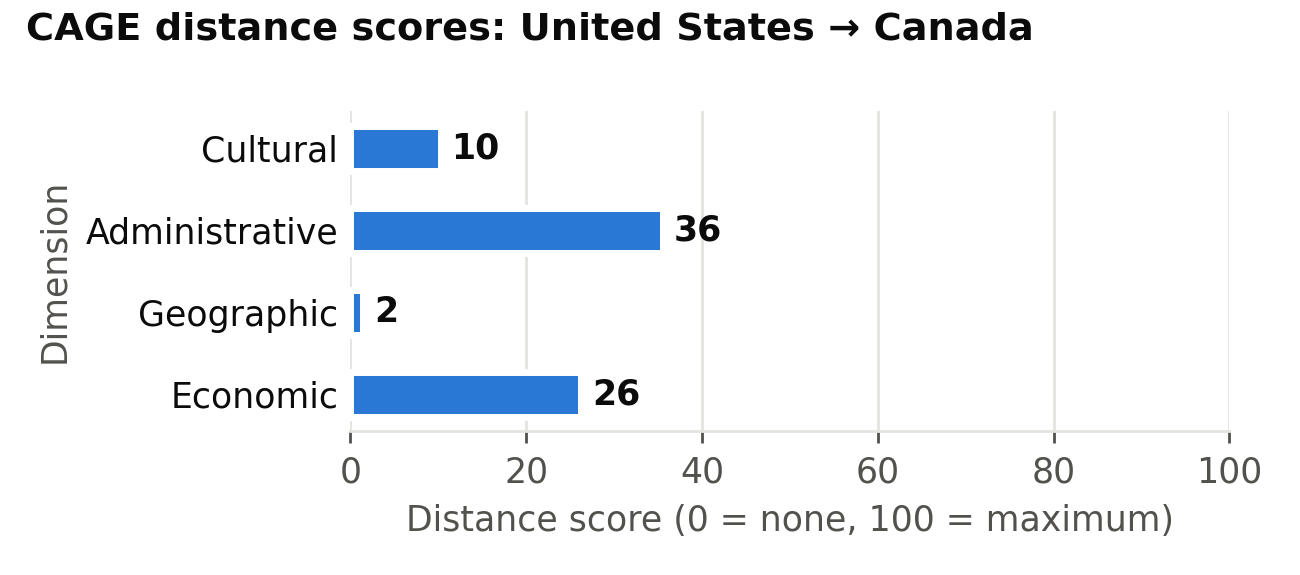

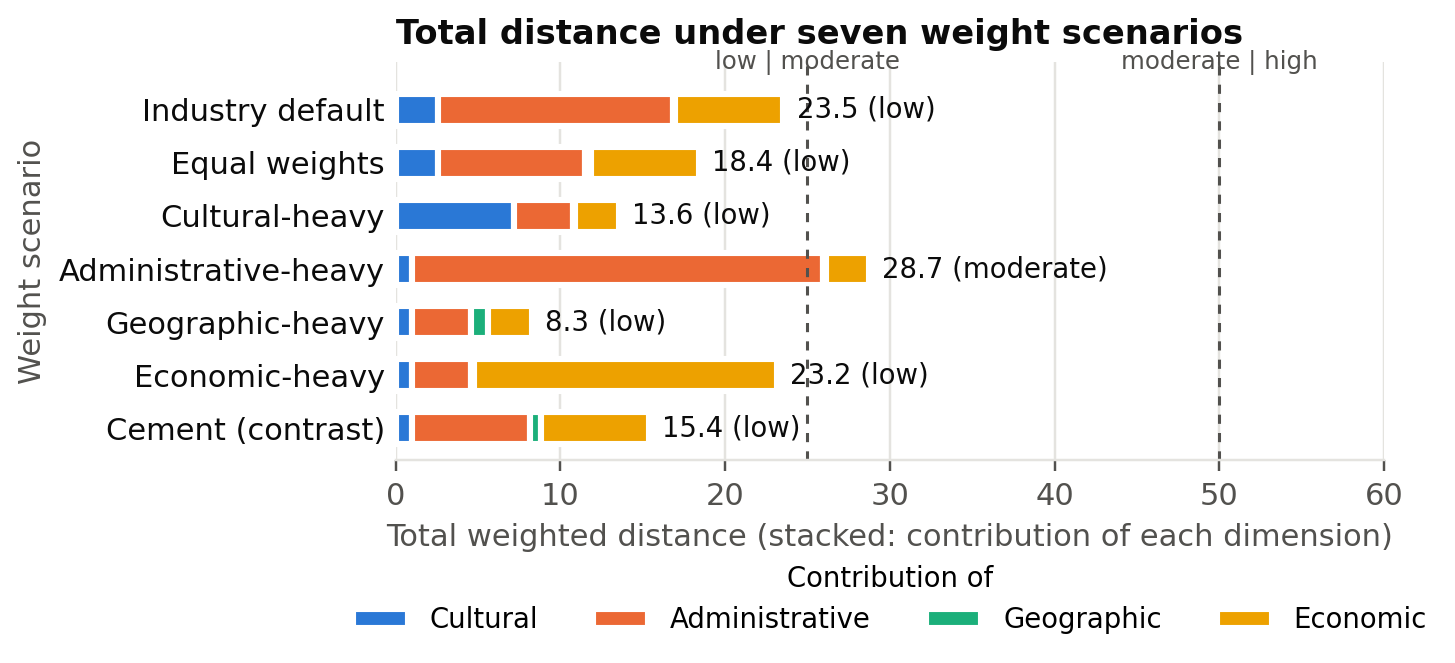

In [12]:
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#ffffff"
SERIES = {"Cultural": "#2a78d6", "Administrative": "#eb6834", "Geographic": "#1baf7a", "Economic": "#eda100"}   # categorical slots 1-4, fixed order
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK})

def bar_chart(res, path, title):
    fig, ax = plt.subplots(figsize=(5.2, 2.3), dpi=250)
    ys = list(range(len(DIMS)))[::-1]
    vals = [res["dims"][d]["score"] or 0 for d in DIMS]
    ax.barh(ys, vals, height=0.55, color="#2a78d6", edgecolor=SURF, linewidth=2)
    for y, v, d in zip(ys, vals, DIMS):
        ax.text(v + 1.2, y, f"{v:.0f}", va="center", ha="left", color=INK, fontsize=10, fontweight="bold")
    ax.set_yticks(ys, DIMS)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Distance score (0 = none, 100 = maximum)")
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_ylabel("Dimension")
    fig.suptitle(title, x=0.02, ha="left", color=INK, fontsize=11, fontweight="bold")   # figure-level, so tight_layout keeps it inside
    fig.tight_layout()
    fig.savefig(path, facecolor=SURF)
    plt.close(fig)

def sensitivity_chart(res, sens_df, path, title):
    fig, ax = plt.subplots(figsize=(6.6, 3.3), dpi=220)
    names = sens_df.scenario.tolist()
    ys = list(range(len(names)))[::-1]
    for y, name in zip(ys, names):
        w = SCEN[name]
        have = {d: res["dims"][d]["score"] for d in DIMS if res["dims"][d]["score"] is not None}
        ws = sum(w[d] for d in have)
        left = 0
        for d in DIMS:
            v = have.get(d, 0) * w[d] / ws
            ax.barh(y, v, left=left, height=0.6, color=SERIES[d], edgecolor=SURF, linewidth=2, label=d if y == ys[0] else None)
            left += v
        ax.text(left + 0.8, y, f"{left:.1f} ({rating(left)})", va="center", ha="left", color=INK, fontsize=9)
    for x, lab in ((THRESHOLDS["low"], "low | moderate"), (THRESHOLDS["high"], "moderate | high")):
        ax.axvline(x, color=INK2, linewidth=1, linestyle=(0, (3, 3)))
        ax.text(x, len(names) - 0.35, lab, ha="center", va="bottom", color=INK2, fontsize=8)
    ax.set_yticks(ys, names)
    ax.set_xlim(0, max(60, sens_df.total.max() + 15))
    ax.set_ylim(-0.6, len(names) - 0.1)
    ax.set_xlabel("Total weighted distance (stacked: contribution of each dimension)")
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_ylabel("Weight scenario")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False, fontsize=9, title="Contribution of", title_fontsize=9)   # below the plot, clear of every label
    ax.set_title(title, loc="left", color=INK, fontsize=11, fontweight="bold")
    fig.tight_layout()
    fig.savefig(path, facecolor=SURF, bbox_inches="tight", pad_inches=0.08)
    plt.close(fig)

bar_chart(R, HERE / "cage_scores.png", f"CAGE distance scores: {R['home_name']} → {R['target_name']}")
sensitivity_chart(R, SENS, HERE / "cage_sensitivity.png", "Total distance under seven weight scenarios")
display(IPImage(filename=str(HERE / "cage_scores.png")))
display(IPImage(filename=str(HERE / "cage_sensitivity.png")))

## 9. Contrast pairs: the tool on other countries

Same code, same rules, same industry weights. These pairs are here only to show the tool works on other pairs and to anchor the thresholds. Their fact tables
(`cage_facts.json`) are shorter than the US-Canada one, so their Administrative scores rest on fewer facts.

In [13]:
CONTRAST = {}
for h, t in CONTRAST_PAIRS:
    r = run_pair(h, t)
    rec = recommendation(r, WEIGHTS)
    CONTRAST[f"{r['home']}-{r['target']}"] = {"res": r, "rec": rec}
rows = [f"| {R['home_name']} → {R['target_name']} (default) | " + " | ".join(f"{scores[d]:.0f}" for d in DIMS) + f" | {TOTAL:.1f} | {RATING} | {REC['risk']} |"]
for k, v in CONTRAST.items():
    r = v["res"]
    rows.append(f"| {r['home_name']} → {r['target_name']} | " + " | ".join(f"{r['dims'][d]['score']:.0f}" if r['dims'][d]['score'] is not None else "–" for d in DIMS) +
                f" | {v['rec']['total']:.1f} | {v['rec']['rating']} | {v['rec']['risk']} |")
show("| Pair | " + " | ".join(DIMS) + " | Total | Rating | Largest risk |\n|---|---|---|---|---|---|---|---|\n" + "\n".join(rows))
for k, v in CONTRAST.items():
    show(f"#### {v['res']['home_name']} → {v['res']['target_name']}\n\n" + "\n\n".join(f"* **{d} {v['res']['dims'][d]['score']:.0f}:** " + " ".join(v["res"]["dims"][d]["notes"]) for d in DIMS))

Pair,Cultural,Administrative,Geographic,Economic,Total,Rating,Largest risk
United States → Canada (default),10,36,2,26,23.5,low,Sales tax regime (GST/HST/PST)
United States → United Kingdom,6,42,37,26,28.6,moderate,Income tax returns and deadlines
United States → Japan,88,54,61,43,60.2,high,Hofstede Kogut-Singh index (6 dims)


## 10. Limits: what this tool cannot see

* **Company-specific factors.** It scores countries, not the firm: its brand, existing Canadian clients, staff who already know Canadian tax, partners, capital, or
  whether estheticians in Canada even want an outside bookkeeper. Ghemawat's framework also has a firm-level side that is not modeled.
* **Regulatory change.** The fact table is a snapshot of official pages on the retrieval dates printed with each source. It does not watch for changes: new CRA rules,
  the USMCA joint review, tariff actions, privacy-law amendments. Severity ratings were assigned by hand and should be checked by a Canadian tax professional before any decision.
* **Rule-based indicators.** Every score is a deterministic rule applied to proxies (Hofstede 2015 data, Factbook religion shares, WGI, World Bank averages). The rules and
  sub-weights are judgments made visible, not estimates fitted to outcomes; a different reasonable rule would give a different number. National averages hide regional
  differences, Quebec most of all (Hofstede rates "Canada French" separately; it is not in the score).
* **Dates.** Indicators are the latest year both countries report in the World Bank API (printed per indicator); Hofstede's data is a 2015 release; the Factbook snapshot is
  frozen because the CIA retired it. Recomputing later can change results.
* **Coverage.** Only Ontario's accounting law was checked among Canada's provinces. The OFAC check matches program names to country names, which misses list-based
  (SDN) exposure. Items that could not be verified are listed below and are not in any score.

In [14]:
UNVERIFIED = []
for k, res in [(f"{A}-{B}", R)] + [(k, v["res"]) for k, v in CONTRAST.items()]:
    for d in DIMS:
        for c in res["dims"][d]["components"]:
            if not c["verified"]:
                UNVERIFIED.append(f"{k} {d}: {c['indicator']} ({c['note'] or 'not available'})")
    for f in res["dims"]["Administrative"]["ctx"]["facts"]:
        if not f["verified"]:
            UNVERIFIED.append(f"{k} Administrative fact '{f['topic']}': " + "; ".join(sorted({c["detail"].split(" for url")[0] + " <" + c["url"] + ">" for c in f["checks"] if not c["ok"]})))
show("**Not verified (left out of every score):**\n\n" + ("\n".join(f"* {u}" for u in UNVERIFIED) if UNVERIFIED else "* nothing"))

In [15]:
# ---------------------------------------------------------------- save results for build_pdf.py
def slim(res):
    out = {k: res[k] for k in ("home", "target", "home_name", "target_name")}
    out["dims"] = {}
    for d in DIMS:
        x = res["dims"][d]
        out["dims"][d] = {"score": x["score"], "notes": x["notes"], "components": x["components"]}
    out["facts"] = res["dims"]["Administrative"]["ctx"]["facts"]
    return out

results = {"generated": TODAY, "industry": INDUSTRY, "weights": WEIGHTS, "weight_rationale": WEIGHT_RATIONALE,
           "contrast_industry": CONTRAST_INDUSTRY, "contrast_weights": CONTRAST_WEIGHTS, "thresholds": THRESHOLDS,
           "pair": slim(R), "scores": scores, "total": TOTAL, "rating": RATING, "equal_total": total_for(R, EQUAL),
           "contrast_total": total_for(R, CONTRAST_WEIGHTS), "recommendation": REC,
           "sensitivity": SENS.to_dict(orient="records"), "flip_text": FLIP_TEXT, "flip": FLIP, "grid_share": share_by_rating,
           "contrast_pairs": {k: {"names": [v["res"]["home_name"], v["res"]["target_name"]],
                                  "scores": {d: v["res"]["dims"][d]["score"] for d in DIMS}, "total": v["rec"]["total"], "rating": v["rec"]["rating"],
                                  "risk": v["rec"]["risk"]} for k, v in CONTRAST.items()},
           "unverified": UNVERIFIED, "factbook_snapshot": FB["_snapshot_date"][:10]}
(HERE / "cage_results.json").write_text(json.dumps(results, indent=1, default=str))
_save_manifest()
print(f"wrote cage_results.json; {A}->{B}: " + ", ".join(f"{d} {scores[d]:.1f}" for d in DIMS) + f"; total {TOTAL:.1f} ({RATING}); risk: {REC['risk']}")

wrote cage_results.json; US->CA: Cultural 10.3, Administrative 35.6, Geographic 1.5, Economic 26.3; total 23.5 (low); risk: Sales tax regime (GST/HST/PST)
